# 04 — Model Training & Comparison
Every regression model is trained with the **same features, the same training rows and the same CV**
(`TimeSeriesSplit(5)`), each inside a `Pipeline(preprocessor → model)`.
The **test set is not used** in this notebook.

In [1]:
# --- Project setup (works locally and on Colab after cloning the repo) ---
import os, sys
from pathlib import Path

ROOT = Path.cwd()
while not (ROOT / "src").is_dir() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))
print("Project root:", ROOT)

Project root: D:\ML


In [2]:
import time
import warnings
import numpy as np
import pandas as pd

from sklearn.pipeline import Pipeline
from sklearn.model_selection import cross_validate
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.preprocessing import PolynomialFeatures
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.svm import SVR
from xgboost import XGBRegressor

from src.preprocessing import make_preprocessor
from src.modeling import load_split, cv_sample, make_cv, SCORING, RANDOM_STATE

warnings.filterwarnings("ignore", category=UserWarning)

X_train, X_test, y_train, y_test = load_split()
print(X_train.shape, X_test.shape)
assert list(X_train.columns) == list(X_test.columns), "column order differs"

(245801, 14) (61451, 14)


### Training rows used for CV
SVR, KNN and Polynomial Regression scale badly with data size (SVR is roughly O(n²)), so 5-fold CV on all 245k rows
would take hours on a laptop or Colab. Every model is therefore compared on the **same fixed 30,000-row sample of the
training set** (`random_state=42`, time order kept). The final model is refit on the full training set in notebook 05.

In [3]:
X_cv, y_cv = cv_sample(X_train, y_train)
cv = make_cv()
print("CV sample:", X_cv.shape, "| surged %:", round((y_cv > 1).mean() * 100, 2))

CV sample: (30000, 14) | surged %: 6.76


### Models
All regression models from the lectures: Linear Regression (closed form, and trained by **gradient descent** with
`SGDRegressor`), Decision Tree, Random Forest, SVR (SVM for regression) and an **ANN** (`MLPRegressor`).
Extra classic models (Ridge, Lasso, Polynomial, KNN) are kept for comparison. Newer versions of the tree models
(XGBoost, LightGBM, HistGradientBoosting) cover bonus B1.

Logistic Regression and Naive Bayes are **classifiers**, and K-means is **clustering**. They do not predict a continuous
value, so they don't apply to this regression task.

In [4]:
from src.model_zoo import MODELS
models = {name: est for name, (group, note, est) in MODELS.items()}
display(pd.DataFrame([(n, g, note) for n, (g, note, _) in MODELS.items()], columns=["Model", "Course group", "Lecture / note"]))

,Model,Course group,Lecture / note
0,Baseline (predict mean),baseline,reference
1,Linear Regression,lecture,L2 (closed form)
2,Linear Regression (Gradient Descent),lecture,L2 + L10 (SGD)
3,Decision Tree,lecture,L4
4,Random Forest,lecture,L4
5,SVR,lecture,L6 (SVM for regression)
6,ANN (MLP),lecture,L9 + L10
7,Ridge,extra,regularised linear
8,Lasso,extra,regularised linear
9,Polynomial Regression (deg 2),extra,linear on poly terms


In [5]:
results = []

for name, estimator in models.items():
    pipeline = Pipeline([
        ("preprocessor", make_preprocessor(X_cv)),
        ("model", estimator),
    ])
    start = time.time()
    try:
        scores = cross_validate(pipeline, X_cv, y_cv, cv=cv, scoring=SCORING, n_jobs=-1)
    except Exception as e:                       # never drop a model silently
        print(f"{name}: FAILED -> {e}")
        results.append({"Model": name, "Error": str(e)})
        continue
    results.append({
        "Model": name,
        "Course group": MODELS[name][0],
        "Mean RMSE": -scores["test_RMSE"].mean(),
        "Std RMSE": scores["test_RMSE"].std(),
        "Mean MSE": -scores["test_MSE"].mean(),
        "Mean R2": scores["test_R2"].mean(),
        "Std R2": scores["test_R2"].std(),
        "Fit time (s)": scores["fit_time"].mean(),
    })
    print(f"{name:32s} RMSE={-scores['test_RMSE'].mean():.5f}  R2={scores['test_R2'].mean():.4f}  ({time.time()-start:.0f}s)")

Baseline (predict mean)          RMSE=0.13366  R2=-0.0003  (7s)


Linear Regression                RMSE=0.13778  R2=-0.0630  (5s)


Linear Regression (Gradient Descent) RMSE=0.15398  R2=-0.3909  (1s)


Decision Tree                    RMSE=0.21464  R2=-1.6126  (1s)


Random Forest                    RMSE=0.14355  R2=-0.1546  (34s)


SVR                              RMSE=0.14435  R2=-0.1718  (172s)


... (4 outputs left out)

KNN                              RMSE=0.14681  R2=-0.2087  (3s)


XGBoost (bonus)                  RMSE=0.15307  R2=-0.3100  (3s)


LightGBM (bonus)                 RMSE=0.13401  R2=-0.0050  (1s)


HistGradientBoosting (bonus)     RMSE=0.13413  R2=-0.0065  (2s)


In [6]:
results_df = pd.DataFrame(results).sort_values("Mean RMSE").reset_index(drop=True)
baseline_rmse = results_df.loc[results_df["Model"].str.startswith("Baseline"), "Mean RMSE"].iloc[0]
results_df["RMSE gain vs baseline %"] = (1 - results_df["Mean RMSE"] / baseline_rmse) * 100
display(results_df.round(5))
results_df.to_csv("reports/model_comparison.csv", index=False)

,Model,Course group,Mean RMSE,Std RMSE,Mean MSE,Mean R2,Std R2,Fit time (s),RMSE gain vs baseline %
0,Lasso,extra,0.13212,0.00652,0.01750,0.02261,0.00265,0.24098,1.15096
1,Baseline (predict mean),baseline,0.13366,0.00652,0.01791,-0.00033,0.00025,0.28282,0.00000
2,LightGBM (bonus),newer,0.13401,0.00758,0.01802,-0.00503,0.01744,0.66927,-0.26753
3,HistGradientBoosting (bonus),newer,0.13413,0.00796,0.01805,-0.00655,0.02133,1.43929,-0.35479
4,Ridge,extra,0.13756,0.01635,0.01919,-0.05938,0.16319,0.22999,-2.91897
5,Linear Regression,lecture,0.13778,0.01678,0.01926,-0.06303,0.17045,0.24767,-3.08545
6,Random Forest,lecture,0.14355,0.00840,0.02068,-0.15464,0.06729,19.21326,-7.40159
7,SVR,lecture,0.14435,0.00274,0.02084,-0.17182,0.07796,49.99772,-8.00304
8,KNN,extra,0.14681,0.00748,0.02161,-0.20866,0.06883,0.22158,-9.83944
9,XGBoost (bonus),newer,0.15307,0.01613,0.02369,-0.30995,0.15481,2.30374,-14.52297


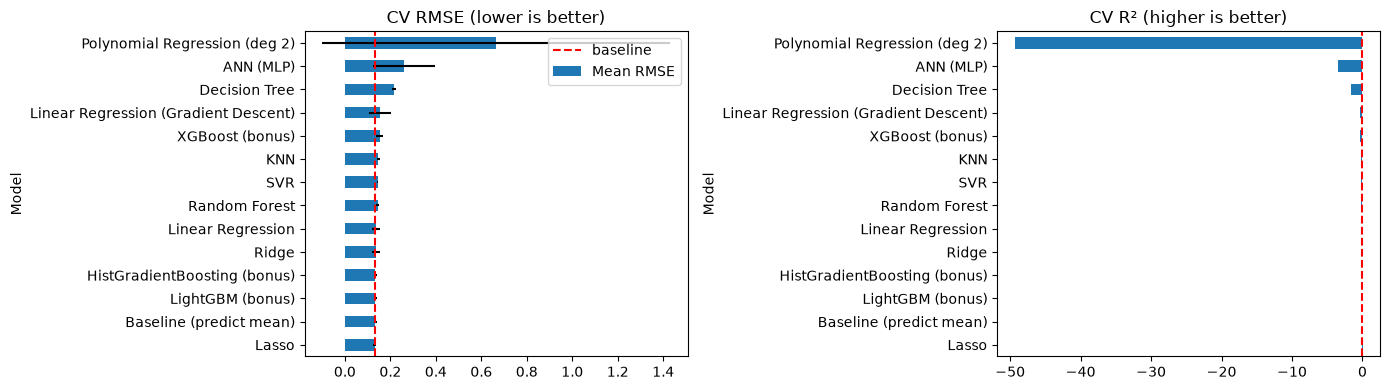

In [7]:
import matplotlib.pyplot as plt
plot = results_df.set_index("Model")
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
plot["Mean RMSE"].plot.barh(ax=axes[0], xerr=plot["Std RMSE"]); axes[0].axvline(baseline_rmse, color="red", ls="--", label="baseline")
axes[0].set_title("CV RMSE (lower is better)"); axes[0].legend()
plot["Mean R2"].plot.barh(ax=axes[1]); axes[1].axvline(0, color="red", ls="--")
axes[1].set_title("CV R² (higher is better)")
plt.tight_layout(); plt.savefig("reports/figures/04_model_comparison.png", dpi=100); plt.show()